In [140]:
from Lee import SE3, se3
import numpy as np
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [141]:
"""
pgo backend

main thing is H * delx = -b

i have a bunch of poses X = {X_n}
the job is to find the set of X that maximimizes the probability P(X | Z)
this probability can be rewritten as P(Z | X) with Bayes' rule
and then after bring it to a maximum likelihood estimation (MLE) format
and using the measurement model of Z to obtain a Gaussian form of P(Z | X)
we can then take the negative log of P(Z | X) and bring the entire thing to 
a minimization problem
This form is now called the negative log likelihood.
This now becomes the objective function we have to minimize.
We make the error a function of some initial guess times a delta and expand that
using a taylor series to the first order where we then obtain e_ij + J_ij delx_ij
Plug that into the objective function and expand to obtain the quadratic where
we have to solve for delx, so we take the derivative of the entire function and evaluate
at 0
this gives us the least squares form H * delx = -b
after solving for delx we do X plus delx

H = J_T omega J
b = e_T omega J

the error is between measurements and the calculated (predicted) odometry
so Z^ - Z or for manifolds, log(Z_-1 Z^) which is just equal to log((XiXj_-1)^-1 Z^)

J is just del error by del delx
for the ith pose, the J is del e by del delx_i
for the jth pose, the J is del e by del delx_j 

The hessian will be N by N for each block, the jacobian N by 1 for each block

"""

"\npgo backend\n\nmain thing is H * delx = -b\n\ni have a bunch of poses X = {X_n}\nthe job is to find the set of X that maximimizes the probability P(X | Z)\nthis probability can be rewritten as P(Z | X) with Bayes' rule\nand then after bring it to a maximum likelihood estimation (MLE) format\nand using the measurement model of Z to obtain a Gaussian form of P(Z | X)\nwe can then take the negative log of P(Z | X) and bring the entire thing to \na minimization problem\nThis form is now called the negative log likelihood.\nThis now becomes the objective function we have to minimize.\nWe make the error a function of some initial guess times a delta and expand that\nusing a taylor series to the first order where we then obtain e_ij + J_ij delx_ij\nPlug that into the objective function and expand to obtain the quadratic where\nwe have to solve for delx, so we take the derivative of the entire function and evaluate\nat 0\nthis gives us the least squares form H * delx = -b\nafter solving for

In [142]:
"""
g2o gives data in 2 forms, vertex indicating the pose number and edge indicating pairs of poses

In the edge we have the i j x y z qx qy qz qw, of which i j are the pose ids used and the rest are the relative measurements
for the vertex we have the id x y z qx qy qz qw, which is the pose number and the pose in the world frame.
"""
"""
g2o describes a pose graph with two kinds of lines: vertices (poses) and edges
(relative measurements between pairs of poses).

VERTEX_SE3:QUAT id x y z qx qy qz qw
  One pose: its id and an initial estimate of its pose in the world frame.
  The number of vertex lines is the number of poses.

EDGE_SE3:QUAT i j x y z qx qy qz qw + 21 values
  i, j are the ids of the two poses involved. The next 7 values are the measured
  pose of j relative to i. The 21 values are the upper triangle of the 6x6
  information matrix (translation first, then rotation).

FIX id
  Holds that pose constant during optimization to anchor the graph.
"""

"""
error, e = log(Z_ij^-1 Xi^-1 Xj)^v this belongs to R^6 (this is pretty much a lie algebra element
if T = Xi^-1 Xj
E = Z_ij^-1 T

start iter until minimal change

H = np.zeros(N, N) #each N has to be a block
b = np.zeros(N, 1) #each entry is a block

    start iter
    T = Xi^-1 @ Xj
    E = Z_ij @ T
    e_ij = E.Log()
    
    Jr, Jr_inv = e.compute_jacobian
    A_ij = -Jr_inv @ T.inverse_pose().Ad()
    B_ij = Jr_inv
    
        H[i][i] += A_ij.T @ omega @ A_ij
        H[i][j] += A_ij.T @ omega @ B_ij
        H[j][i] += B_ij.T @ omega @ A_ij
        H[j][j] += B_ij.T @ omega @ B_ij 
        
        
        b[i] += A_ij.T @ omega @ e_ij
        b[j] += B_ij.T @ omega @ e_ij
    
    or 
    
        J_ij = np.zeros(1, N)
        J_ij[i] = A_ij
        J_ij[j] = B_ij
        
        H += J_ij.T @ omega @ J_ij
        b += J_ij.T @ omega @ e_ij 
    
    next iter
    end iter
    
solve now for H * delx = -b
X boxplus delx
next iter
"""

'\nerror, e = log(Z_ij^-1 Xi^-1 Xj)^v this belongs to R^6 (this is pretty much a lie algebra element\nif T = Xi^-1 Xj\nE = Z_ij^-1 T\n\nstart iter until minimal change\n\nH = np.zeros(N, N) #each N has to be a block\nb = np.zeros(N, 1) #each entry is a block\n\n    start iter\n    T = Xi^-1 @ Xj\n    E = Z_ij @ T\n    e_ij = E.Log()\n    \n    Jr, Jr_inv = e.compute_jacobian\n    A_ij = -Jr_inv @ T.inverse_pose().Ad()\n    B_ij = Jr_inv\n    \n        H[i][i] += A_ij.T @ omega @ A_ij\n        H[i][j] += A_ij.T @ omega @ B_ij\n        H[j][i] += B_ij.T @ omega @ A_ij\n        H[j][j] += B_ij.T @ omega @ B_ij \n        \n        \n        b[i] += A_ij.T @ omega @ e_ij\n        b[j] += B_ij.T @ omega @ e_ij\n    \n    or \n    \n        J_ij = np.zeros(1, N)\n        J_ij[i] = A_ij\n        J_ij[j] = B_ij\n        \n        H += J_ij.T @ omega @ J_ij\n        b += J_ij.T @ omega @ e_ij \n    \n    next iter\n    end iter\n    \nsolve now for H * delx = -b\nX boxplus delx\nnext iter\n'

In [143]:
# each pose will be a SE3 element
#each edge will be a Edge()

class Edge:
    def __init__(self, line): #takes the g2o thing directly as a string
        tok = line.split() #split each line/token
        if tok[0] != "EDGE_SE3:QUAT":
            raise ValueError(f"not an EDGE_SE3:QUAT line: {tok[0]}")
        if len(tok) != 31:   # tag + 2 ids + 3 trans + 4 quat + 21 information mat stuff
            raise ValueError(f"expected 31 tokens, got {len(tok)}")

        self.i, self.j = int(tok[1]), int(tok[2])
        self.key = (self.i, self.j)

        vals = np.array(tok[3:], dtype=float)
        # print(vals)

        trans = vals[0:3]
        quat = vals[3:7] / np.linalg.norm(vals[3:7])
        # print(quat)
        self.Z = SE3(tuple(quat), trans)

        I = np.zeros((6, 6))
        I[np.triu_indices(6)] = vals[7:]
        self.omega_g2o = I + np.triu(I, 1).T

        S = np.diag([1, 1, 1, 0.5, 0.5, 0.5])
        self.omega = S @ self.omega_g2o @ S

In [144]:
def g2o_vertex_pipeline(pose_list, line): #give it empty list and token 
    tok = line.split() 
    if tok[0] != "VERTEX_SE3:QUAT":
        # print(f"not an VERTEX_SE3:QUAT line: {tok[0]}")
        return pose_list
    if len(tok) != 9:   # tag + 1 ids + 3 trans + 4 quat
        # print(f"expected 9 tokens, got {len(tok)}")
        return pose_list
    id = int(tok[1])
    vals = np.array(tok[2:], dtype=float)
    # print(len(vals))
    
    trans = vals[0:3]
    quat = vals[3:7] / np.linalg.norm(vals[3:7])
    X = SE3(tuple(quat), trans)

    if id >= len(pose_list):
        pose_list.extend([None] * (id + 1 - len(pose_list))) #makes it longer by 1 + id 
    if pose_list[id] is not None:
        raise ValueError(f"duplicate vertex id {id}")
    pose_list[id] = X
    
    return pose_list
    

In [145]:
# todo
# test both the Edge and the vertex pipeline (done)
# we init a loop (for now it will just be a for loop of maybe 10 but later it has to relate to the overall error of the trajectory)
# for the main algorithm, we will be iterating through each edge from which we will be using the edges measurement (Z)
# and from th edge, we will take the i and j value and use that to access the ith and jth pose from the pose_list 
# in the loop we initialize the hessian and the bias. 
# then we start another loop for each edge and begin the actual algorithm where the goal is solving for delx

# after this is properly done, we will make a class version of this that will be group agnostic (i.e. has to work for SE3 and SE2)

In [146]:
filepath = "dummy_se3.g2o"
edge_list = []
pose_list = []
with open(filepath, "r") as f:
    for line in f:
        # print(line)
        if line.startswith("EDGE_SE3:QUAT"):
            edge_list.append(Edge(line))
        pose_list = g2o_vertex_pipeline(pose_list, line)

In [147]:
print(pose_list[0].X)
# print(pose_list[0].R)
# print(pose_list[0].t)
print(pose_list[1].X)
# print(pose_list[1].R)
# print(pose_list[1].t)

[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
[[ 0.99916206  0.02244102 -0.03422823  1.015236  ]
 [-0.02299992  0.99960705 -0.0160231  -0.051999  ]
 [ 0.0338552   0.01679692  0.99928559  0.053148  ]
 [ 0.          0.          0.          1.        ]]


In [148]:
print(edge_list[0].Z.X)

[[ 0.99916206  0.02244102 -0.03422823  1.015236  ]
 [-0.02299992  0.99960705 -0.0160231  -0.051999  ]
 [ 0.0338552   0.01679692  0.99928559  0.053148  ]
 [ 0.          0.          0.          1.        ]]


In [149]:
from scipy.linalg import cho_factor, cho_solve

d = 6 # d-dimensional, for SE3, d will be 6 and for SE2 it will be 3
N = len(pose_list)
print(N)
loop_num = 20

for loop in range(loop_num):
    #main loop
    H = np.zeros((d * N, d * N))
    b = np.zeros(d * N)
    
    for edge in edge_list:
        i, j = edge.key
        X_i, X_j = pose_list[edge.i], pose_list[edge.j] #returns SE3
        Z_ij = edge.Z #returns SE3
        omega = edge.omega
        
        T = X_i.inverse_pose() @ X_j
        E = Z_ij.inverse_pose() @ T
        e_ij = E.log_map() #this returns the se3 object, not the vector itself, that would be e_ij.vee
        e_ij_vector = e_ij.vee
    
        Jr, Jr_inv = e_ij.compute_left_jacobians(right=True)
    
        A_ij = -Jr_inv @ T.inverse_pose().Ad()
        B_ij = Jr_inv
    
        H[i * d : i * d + d, i * d : i * d + d] += A_ij.T @ omega @ A_ij
        H[i * d : i * d + d, j * d : j * d + d] += A_ij.T @ omega @ B_ij
        H[j * d : j * d + d, i * d : i * d + d] += B_ij.T @ omega @ A_ij
        H[j * d : j * d + d, j * d : j * d + d] += B_ij.T @ omega @ B_ij 
        
        
        b[i * d: i * d + d] += A_ij.T @ omega @ e_ij_vector
        b[j * d: j * d + d] += B_ij.T @ omega @ e_ij_vector
    
    c, low = cho_factor(H[d:, d:])
    delx = np.zeros(d * N)
    delx[d:] = cho_solve((c, low), -b[d:])
    
    for n in range(N):
        delta_x = delx[n * d : n * d + d]
        pose_list[n] = pose_list[n].boxplus(delta_x)
    
    # print(delx)
    # print(type(delx))
    # print(len(delx))
    #end main loop

97


initial guess   ATE 0.723 m (max 1.318)   rot RMSE 6.56 deg   RPE 0.0850 m
GN estimate     ATE 0.275 m (max 0.451)   rot RMSE 2.81 deg   RPE 0.0803 m


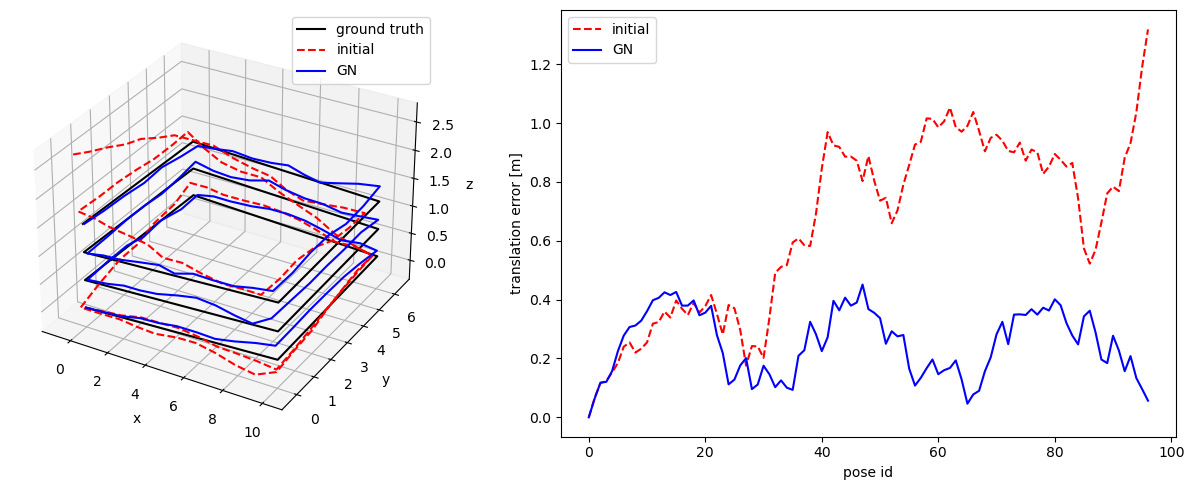

In [150]:

# ---- compare against ground truth ----
import matplotlib.pyplot as plt
from Lee import SO_n

gt_list = []
with open("dummy_se3_groundtruth.g2o", "r") as f:
    for line in f:
        gt_list = g2o_vertex_pipeline(gt_list, line)

init_list = []
with open("dummy_se3.g2o", "r") as f:
    for line in f:
        init_list = g2o_vertex_pipeline(init_list, line)

assert len(gt_list) == len(pose_list)

def trans_errors(est, gt):
    return np.array([np.linalg.norm(e.t_flat - g.t_flat) for e, g in zip(est, gt)])

def rot_errors_deg(est, gt):
    # angle of R_gt^T R_est, i.e. the rotation still needed to get from truth to estimate
    return np.degrees([SO_n(g.R.T @ e.R).log_map().theta for e, g in zip(est, gt)])

def rpe(est, gt):
    # error of each relative step i -> i+1; doesn't depend on the global frame
    errs = []
    for k in range(len(gt) - 1):
        d_est = est[k].inverse_pose() @ est[k + 1]
        d_gt = gt[k].inverse_pose() @ gt[k + 1]
        errs.append(np.linalg.norm(d_est.t_flat - d_gt.t_flat))
    return np.sqrt(np.mean(np.square(errs)))

for name, P in [("initial guess", init_list), ("GN estimate", pose_list)]:
    te, re = trans_errors(P, gt_list), rot_errors_deg(P, gt_list)
    print(f"{name:14s}  ATE {np.sqrt(np.mean(te**2)):.3f} m (max {te.max():.3f})   "
          f"rot RMSE {np.sqrt(np.mean(re**2)):.2f} deg   RPE {rpe(P, gt_list):.4f} m")

def xyz(P):
    return np.array([p.t_flat for p in P])

fig = plt.figure(figsize=(13, 5))
ax = fig.add_subplot(1, 2, 1, projection="3d")
for P, label, style in [(gt_list, "ground truth", "k-"), (init_list, "initial", "r--"), (pose_list, "GN", "b-")]:
    p = xyz(P)
    ax.plot(p[:, 0], p[:, 1], p[:, 2], style, label=label)
ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("z"); ax.legend()

ax2 = fig.add_subplot(1, 2, 2)
ax2.plot(trans_errors(init_list, gt_list), "r--", label="initial")
ax2.plot(trans_errors(pose_list, gt_list), "b-", label="GN")
ax2.set_xlabel("pose id"); ax2.set_ylabel("translation error [m]"); ax2.legend()
plt.tight_layout(); plt.show()